# CYP3A4 inhibitor classification: k-NN, random forest and SVM

The training and test sets come from `ShuffleandSplit` and are the same splits used for the MOE Binary QSAR models. A compound with an Activity Score of 40 or above is an inhibitor (1); everything below 40, including inconclusive compounds, is a non-inhibitor (0).

In [1]:
%matplotlib inline
from cyp_models import (
    CLASSIFIERS, evaluate, load_split, plot_calibration, rf_calibration, roc_test,
)

In [2]:
X_train, y_train, X_test, y_test = load_split("3a4")
print(f"Training: {len(y_train)} compounds, {y_train.sum()} inhibitors, "
      f"{len(y_train) - y_train.sum()} non-inhibitors")
print(f"Test:     {len(y_test)} compounds, {y_test.sum()} inhibitors, "
      f"{len(y_test) - y_test.sum()} non-inhibitors")
print(f"Features: {X_train.shape[1]} MOE 2-D descriptors")

Training: 8427 compounds, 4234 inhibitors, 4193 non-inhibitors
Test:     2107 compounds, 1033 inhibitors, 1074 non-inhibitors
Features: 186 MOE 2-D descriptors


## Classifiers

Hyperparameters match the scikit-learn 0.15 defaults used in the original analysis.

In [3]:
CLASSIFIERS

{'k-NN': KNeighborsClassifier(),
 'Random Forest': RandomForestClassifier(n_estimators=10, random_state=0),
 'SVM': SVC(gamma='auto')}

## Validation

- **Training set:** 5-fold cross-validation.
- **Test set:** each model is fit on the full training set and then predicts the held-out test set. The scaler is part of the pipeline, so it too is fit on training data only.

In [4]:
results, test_confusion = evaluate(X_train, y_train, X_test, y_test)
results

,Method,Set,Accuracy,TPR,TNR
0,k-NN,Training (5-fold CV),0.714,0.766,0.662
1,k-NN,Test,0.704,0.749,0.660
2,Random Forest,Training (5-fold CV),0.718,0.685,0.751
3,Random Forest,Test,0.728,0.694,0.761
4,SVM,Training (5-fold CV),0.754,0.814,0.694
5,SVM,Test,0.746,0.802,0.692


## Test set confusion matrices

Rows are actual classes and columns are predicted classes, in the order non-inhibitor, inhibitor.

In [5]:
for name, cm in test_confusion.items():
    print(name)
    print(cm, end='\n\n')

k-NN
[[709 365]
 [259 774]]

Random Forest
[[817 257]
 [316 717]]

SVM
[[743 331]
 [205 828]]



## Random forest calibration

Each point is a bin of predicted probability (rounded to the nearest 0.1, since the forest has 10 trees). Its height is the fraction of compounds given that probability that are actually inhibitors, and its area is proportional to the number of such compounds. Points on the diagonal are perfectly calibrated.

,pred_prob,count,observed_freq
0,0.0,183,0.043716
1,0.1,176,0.096591
2,0.2,174,0.201149
3,0.3,185,0.340541
4,0.4,209,0.363636
5,0.5,211,0.559242
6,0.6,215,0.558140
7,0.7,211,0.701422
8,0.8,198,0.747475
9,0.9,208,0.850962


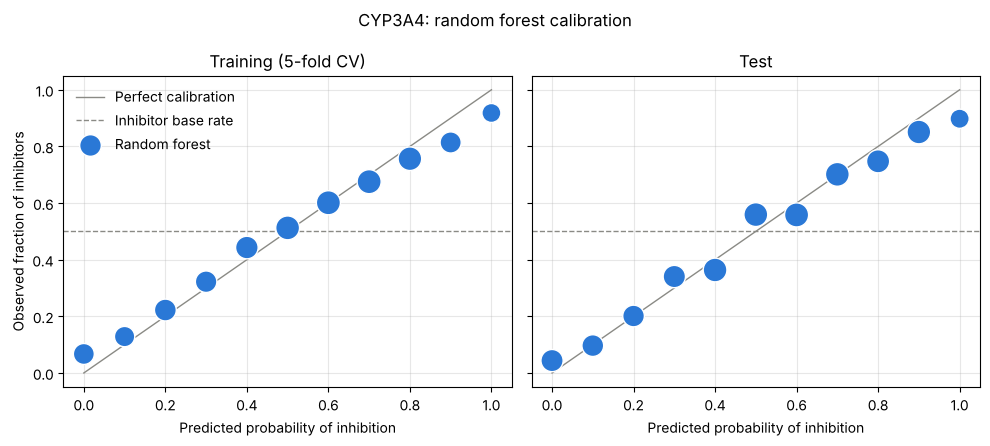

In [6]:
calibration = rf_calibration(X_train, y_train, X_test, y_test)
fig = plot_calibration(calibration, baseline=y_train.mean(), title="CYP3A4: random forest calibration")
fig.savefig("results/3a4_rf_calibration.png", dpi=150)
calibration["Test"]

## ROC curves on the test set

Each model is fit on the training set. Random forest and k-NN are scored by predicted probability, the SVM by its decision function.

,Method,Test AUC
0,k-NN,0.771
1,Random Forest,0.815
2,SVM,0.831


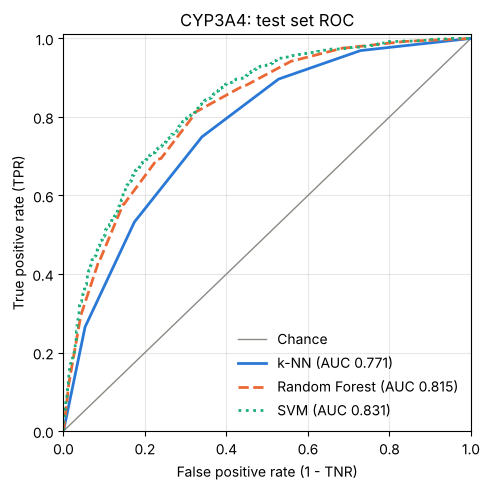

In [7]:
auc, fig = roc_test(X_train, y_train, X_test, y_test, title="CYP3A4: test set ROC")
fig.savefig("results/3a4_roc.png", dpi=150)
auc

In [8]:
results.merge(auc.assign(Set="Test"), how="left").to_csv("results/3a4.csv", index=False)